## 1. Build the user profiles (M3)

K-Means can only compare numbers, so each user is turned into one row of 20 features that describe their taste:
- **18 genre shares**: the share of the user's ratings that include each genre (what they watch)
- **mean_rating**: the user's average rating (how much they enjoy what they watch)
- **log_n_ratings**: log of the user's number of ratings (how active they are)

We use shares, not counts, because users rate between 18 and 31,273 movies (see 01_data_eda). With counts, K-Means would separate active users from casual users instead of different tastes. Activity is kept as one feature, with log so very active users cannot dominate.

In [10]:
# Lets this notebook import our shared functions from the src/ folder
import sys
sys.path.append('..')

import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score

SEED = 42
DATA = '../data/'
FIG = '../figures/'

In [11]:
ratings = pd.read_parquet(DATA + 'clean_ratings.parquet')
movies = pd.read_parquet(DATA + 'movies_clean.parquet')
GENRES = [c for c in movies.columns if c != 'movieId']

print(ratings.shape, movies.shape, len(GENRES), 'genres')

(31944676, 3) (80504, 19) 18 genres


### Genre shares
For each genre, we count how many of the user's ratings are of a movie in that genre, then divide by the user's total number of ratings.
We do one genre at a time because joining all 18 genre columns onto 32 million ratings at once would need several GB of memory.
A user's shares can add up to more than 1, because a movie with several genres counts toward each of them.

In [12]:
n_ratings = ratings.groupby('userId').size()

genre_counts = {}
for g in GENRES:
    movies_in_g = movies.loc[movies[g], 'movieId']   # movie IDs that have this genre
    in_g = ratings['movieId'].isin(movies_in_g)      # True for each rating of such a movie
    genre_counts[g] = in_g.groupby(ratings['userId']).sum()

genre_counts = pd.DataFrame(genre_counts)
shares = genre_counts.div(n_ratings, axis=0)         # counts -> shares

shares.head()

,Action,Adventure,Animation,Children,Comedy,Crime,Documentary,Drama,Fantasy,Film-Noir,Horror,Musical,Mystery,Romance,Sci-Fi,Thriller,War,Western
userId,,,,,,,,,,,,,,,,,,
1,0.134752,0.120567,0.000000,0.014184,0.361702,0.113475,0.007092,0.723404,0.056738,0.007092,0.021277,0.000000,0.070922,0.255319,0.120567,0.113475,0.156028,0.014184
2,0.173077,0.134615,0.153846,0.211538,0.500000,0.115385,0.000000,0.461538,0.076923,0.000000,0.019231,0.134615,0.019231,0.403846,0.000000,0.211538,0.038462,0.000000
3,0.394558,0.394558,0.081633,0.136054,0.367347,0.108844,0.000000,0.360544,0.115646,0.000000,0.027211,0.068027,0.020408,0.238095,0.238095,0.217687,0.081633,0.020408
4,0.407407,0.185185,0.000000,0.000000,0.259259,0.111111,0.000000,0.296296,0.111111,0.000000,0.259259,0.000000,0.148148,0.000000,0.185185,0.444444,0.074074,0.000000
5,0.424242,0.393939,0.090909,0.121212,0.272727,0.272727,0.000000,0.393939,0.060606,0.000000,0.060606,0.090909,0.030303,0.121212,0.151515,0.484848,0.090909,0.030303


### Add mean rating and activity, then check

In [13]:
profiles = shares.copy()
profiles['mean_rating'] = ratings.groupby('userId')['rating'].mean()
profiles['log_n_ratings'] = np.log(n_ratings)

print('Shape:', profiles.shape)
print('Missing values:', profiles.isna().sum().sum())
print('All shares between 0 and 1:', ((shares >= 0) & (shares <= 1)).all().all())
print('Average genre shares, highest first:')
print(shares.mean().sort_values(ascending=False).round(3))
profiles[['mean_rating', 'log_n_ratings']].describe().round(3)

Shape: (200948, 20)
Missing values: 0
All shares between 0 and 1: True
Average genre shares, highest first:
Drama          0.444
Comedy         0.341
Action         0.318
Thriller       0.280
Adventure      0.260
Sci-Fi         0.186
Romance        0.182
Crime          0.182
Fantasy        0.117
Children       0.090
Mystery        0.081
Animation      0.072
Horror         0.063
War            0.056
Musical        0.037
Western        0.019
Documentary    0.008
Film-Noir      0.008
dtype: float64


,mean_rating,log_n_ratings
count,200948.000,200948.000
mean,3.704,4.439
std,0.487,1.028
min,0.500,2.890
25%,3.415,3.584
50%,3.725,4.290
75%,4.025,5.112
max,5.000,10.351


### Scale and save
K-Means measures distances between users. The shares are between 0 and 1, mean_rating between 0.5 and 5, and log_n_ratings between about 3 and 10, so without scaling the features with bigger numbers would control the distances. StandardScaler gives every feature mean 0 and standard deviation 1.

We save two files:
- `user_profiles.parquet` (scaled): used by K-Means and by Abdallah's PCA and stability checks
- `user_profiles_raw.parquet` (not scaled): used to describe the clusters in easy numbers, e.g. "this group's Action share is 35%"

In [14]:

scaler = StandardScaler()
scaled = pd.DataFrame(scaler.fit_transform(profiles),
index=profiles.index, columns=profiles.columns)

profiles.reset_index().to_parquet(DATA + 'user_profiles_raw.parquet', index=False)
scaled.reset_index().to_parquet(DATA + 'user_profiles.parquet', index=False)

print('Saved. Scaled shape:', scaled.shape)
scaled.describe().T[['mean', 'std']].round(2)

Saved. Scaled shape: (200948, 20)


,mean,std
Action,-0.0,1.0
Adventure,-0.0,1.0
Animation,0.0,1.0
Children,0.0,1.0
Comedy,-0.0,1.0
Crime,-0.0,1.0
Documentary,0.0,1.0
Drama,0.0,1.0
Fantasy,-0.0,1.0
Film-Noir,-0.0,1.0


## 2. K-Means clustering (M4)

### Choosing k
We run K-Means for k = 2 to 10 on the scaled profiles and record three measures for each k:
- **Inertia** (Elbow method): total distance from each user to their cluster center. It always drops as k grows, so we look for where it stops dropping fast.
- **Silhouette score**: how well each user fits their own cluster compared with the nearest other one. Higher is better. It is computed on 20,000 random users, because the full calculation compares every pair of 200,948 users and is too slow.
- **Davies-Bouldin index**: how similar each cluster is to its closest neighbor. Lower is better.

We also record the size of the smallest cluster, because a very small cluster is not a useful audience segment and gives weak association rules.

In [15]:
X = scaled.values

results = []
for k in range(2, 11):
    start = time.time()
    km = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(X)
    results.append({
        'k': k,
        'inertia': km.inertia_,
        'silhouette': silhouette_score(X, km.labels_, sample_size=20000, random_state=SEED),
        'davies_bouldin': davies_bouldin_score(X, km.labels_),
        'smallest_cluster': np.bincount(km.labels_).min(),
    })
    print(f'k={k} done in {time.time() - start:.0f}s')

k_results = pd.DataFrame(results)
k_results.round(3)

k=2 done in 9s
k=3 done in 7s
k=4 done in 6s
k=5 done in 7s
k=6 done in 9s
k=7 done in 8s
k=8 done in 9s
k=9 done in 9s
k=10 done in 10s


,k,inertia,silhouette,davies_bouldin,smallest_cluster
0,2,3523074.804,0.123,2.437,94759
1,3,3163493.502,0.125,2.105,35331
2,4,2946779.586,0.121,2.033,20611
3,5,2810056.160,0.096,2.139,19302
4,6,2703519.477,0.097,2.051,18779
5,7,2605589.106,0.093,1.943,4498
6,8,2515477.769,0.092,1.964,3979
7,9,2442418.956,0.096,1.892,3434
8,10,2373279.493,0.099,1.826,3079


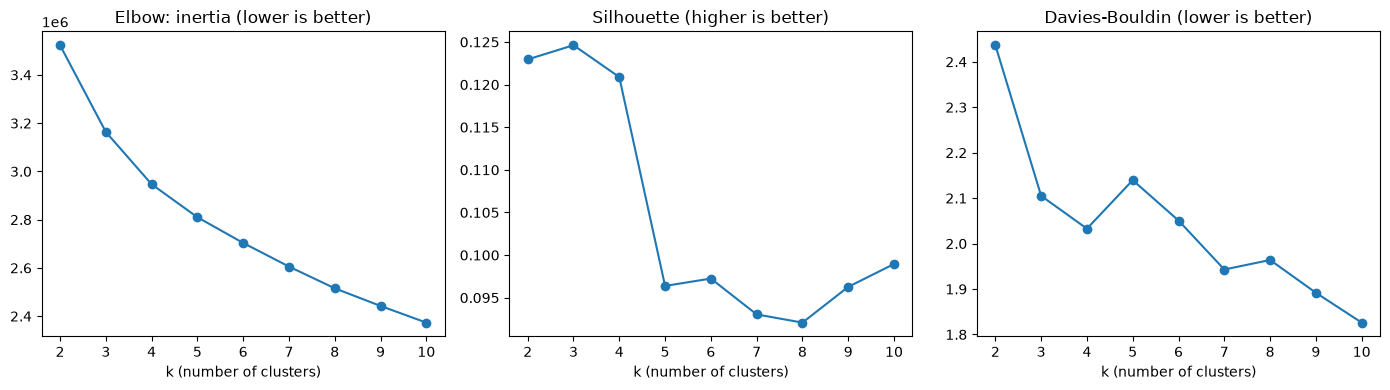

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col, title in zip(axes,
        ['inertia', 'silhouette', 'davies_bouldin'],
        ['Elbow: inertia (lower is better)', 'Silhouette (higher is better)', 'Davies-Bouldin (lower is better)']):
    ax.plot(k_results['k'], k_results[col], marker='o')
    ax.set_xlabel('k (number of clusters)')
    ax.set_title(title)
plt.tight_layout()
plt.savefig(FIG + 'kmeans_choose_k.png', dpi=150)
plt.show()

### Chosen k = 4
- **Elbow:** inertia drops by 10% (k=2 to 3) and 7% (k=3 to 4), then only 3-5% per extra cluster, so the curve bends at k=4.
- **Silhouette:** k=2 to 4 are almost equal (0.121-0.125), then it falls sharply to 0.096 at k=5.
- **Davies-Bouldin:** k=4 (2.03) is lower than k=2, 3 and 5.
- **Cluster size:** from k=7 the smallest cluster is about 2% of users or less, too small to be a useful segment. At k=4 the smallest cluster has 20,611 users (10%).

Limitation: a silhouette of about 0.12 means the clusters overlap. User tastes change gradually rather than falling into fully separate groups.

In [17]:
K = 4
km_final = KMeans(n_clusters=K, n_init=10, random_state=SEED).fit(X)

cluster_labels = pd.DataFrame({'userId': scaled.index, 'cluster': km_final.labels_})
cluster_labels.to_csv(DATA + 'cluster_labels.csv', index=False)

print('Saved cluster_labels.csv:', cluster_labels.shape)
print(cluster_labels['cluster'].value_counts().sort_index())

Saved cluster_labels.csv: (200948, 2)
cluster
0    45933
1    71577
2    20611
3    62827
Name: count, dtype: int64


In [19]:
summary = profiles.groupby(km_final.labels_).mean().T
summary['all users'] = profiles.mean()
summary.loc['median_n_ratings'] = (list(n_ratings.groupby(km_final.labels_).median()) + [n_ratings.median()])
summary.loc['size'] = list(np.bincount(km_final.labels_)) + [len(profiles)]
summary.round(3)

,0,1,2,3,all users
Action,0.284,0.218,0.296,0.464,0.318
Adventure,0.180,0.189,0.401,0.353,0.260
Animation,0.034,0.054,0.226,0.070,0.072
Children,0.037,0.084,0.259,0.079,0.090
Comedy,0.248,0.429,0.417,0.284,0.341
Crime,0.268,0.145,0.103,0.186,0.182
Documentary,0.010,0.012,0.005,0.004,0.008
Drama,0.563,0.480,0.332,0.351,0.444
Fantasy,0.072,0.099,0.239,0.132,0.117
Film-Noir,0.019,0.007,0.002,0.004,0.008


In [20]:
# How much each cluster's genre shares differ from the average user
diff = summary.loc[GENRES].drop(columns='all users').sub(summary.loc[GENRES, 'all users'], axis=0)
diff.round(3)

,0,1,2,3
Action,-0.034,-0.100,-0.022,0.146
Adventure,-0.080,-0.071,0.141,0.093
Animation,-0.038,-0.018,0.154,-0.002
Children,-0.053,-0.006,0.169,-0.010
Comedy,-0.093,0.088,0.076,-0.057
Crime,0.086,-0.037,-0.079,0.004
Documentary,0.002,0.003,-0.004,-0.004
Drama,0.119,0.037,-0.111,-0.092
Fantasy,-0.045,-0.019,0.121,0.014
Film-Noir,0.011,-0.002,-0.006,-0.004


### The 4 audience groups
| Cluster | Size | Name | What makes it different from the average user |
|---|---|---|---|
| 0 | 45,933 (23%) | Drama & crime fans | More Drama (+12 pts), Crime (+9), Thriller (+7), Mystery (+4); less Comedy and Adventure. Highest mean rating (3.87). |
| 1 | 71,577 (36%) | Comedy & romance fans | More Comedy (+9), Romance (+7); less Action (-10), Adventure, Sci-Fi. Lowest mean rating (3.57), most active (median 85 ratings). |
| 2 | 20,611 (10%) | Family & animation fans | More Children (+17), Animation (+15), Adventure (+14), Fantasy (+12), Musical (+6); less Drama and Thriller. |
| 3 | 62,827 (31%) | Action & sci-fi fans | More Action (+15), Sci-Fi (+10), Adventure (+9), Thriller (+6); less Drama, Comedy, Romance. |

No group forms around rare genres such as Documentary or Film-Noir (under 2% share in every cluster).

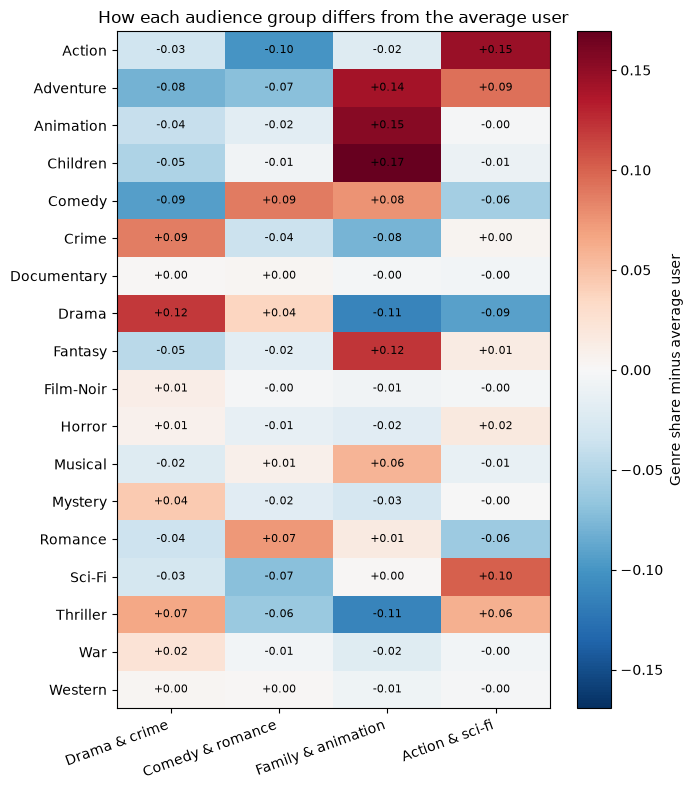

In [21]:
CLUSTER_NAMES = {0: 'Drama & crime', 1: 'Comedy & romance',2: 'Family & animation', 3: 'Action & sci-fi'}
diff_named = diff.rename(columns=CLUSTER_NAMES)

fig, ax = plt.subplots(figsize=(7, 8))
lim = np.abs(diff_named.values).max()
im = ax.imshow(diff_named.values, cmap='RdBu_r', vmin=-lim, vmax=lim, aspect='auto')

ax.set_xticks(range(K))
ax.set_xticklabels(diff_named.columns, rotation=20, ha='right')
ax.set_yticks(range(len(GENRES)))
ax.set_yticklabels(diff_named.index)
for i in range(len(GENRES)):
    for j in range(K):
        ax.text(j, i, f'{diff_named.iloc[i, j]:+.2f}', ha='center', va='center', fontsize=8)

fig.colorbar(im, label='Genre share minus average user')
ax.set_title('How each audience group differs from the average user')
plt.tight_layout()
plt.savefig(FIG + 'cluster_genre_differences.png', dpi=150)
plt.show()